# Import libraries

In [152]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

# Load the dataset

In [153]:
df = pd.read_csv("titanic.csv")

### Check the first five rows:

In [154]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


#### information of the dataset

In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


#### Statistical summary

In [156]:
df.describe(include='all')

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### count of null values

In [157]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [158]:
df['deck_known'] = df['deck'].notna().astype(int)

In [159]:
df.drop('deck', axis=1, inplace=True)

In [160]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,deck_known
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,0
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,1
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,0
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,1
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,0


In [161]:
df.shape

(891, 15)

In [162]:
df.duplicated().sum()

np.int64(107)

In [163]:
df = df.drop_duplicates()

In [164]:
df.shape

(784, 15)

Handle missing age

age has 177 missing values.

We should not drop 177 passengers just because age is missing.

Instead, we'll fill missing age values using the median.

Why median?

Because age can contain extreme values, and median is more robust to outliers than mean.

In [165]:
df['age'] = df['age'].fillna(df['age'].median())

In [166]:
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

In [167]:
df.drop('alive', axis=1, inplace=True)

In [168]:
df.drop(['who'], axis=1, inplace=True)

The +1 represents the passenger themselves.

In [169]:
df['family_size'] = df['sibsp'] + df['parch'] + 1

These two columns are often confusing:

SibSp

Number of siblings + spouses aboard

Parch

Number of parents + children aboard

In [170]:
df.drop(['sibsp', 'parch'], axis=1, inplace=True)

remove alone and let family_size represent this information.

In [171]:
df.drop('alone', axis=1, inplace=True)

adult_male is essentially derived from information already present in the dataset, particularly sex and age.

In [172]:
df.drop('adult_male', axis=1, inplace=True)

In [173]:
df.drop('class', axis=1, inplace=True)

In [174]:
df[['embarked', 'embark_town']].head(10)

,embarked,embark_town
0,S,Southampton
1,C,Cherbourg
2,S,Southampton
3,S,Southampton
4,S,Southampton
5,Q,Queenstown
6,S,Southampton
7,S,Southampton
8,S,Southampton
9,C,Cherbourg


In [175]:
df.drop('embark_town', axis=1, inplace=True)

In [176]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
fare           0
embarked       0
deck_known     0
family_size    0
dtype: int64

## Survival counts

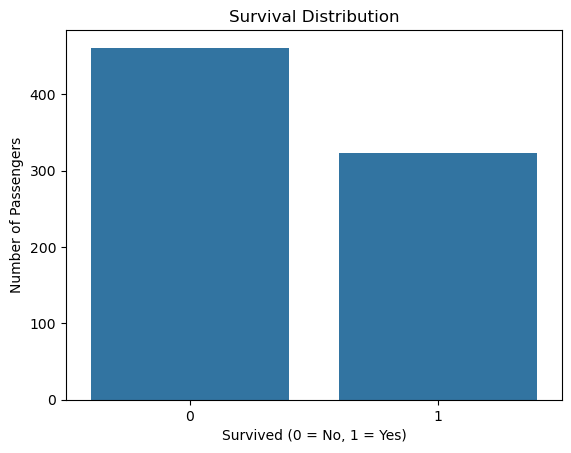

In [177]:
sns.countplot(x='survived', data=df)

plt.title('Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

In [178]:
survival_percentage = df['survived'].value_counts(normalize=True) * 100

print(survival_percentage)

survived
0    58.80102
1    41.19898
Name: proportion, dtype: float64


In [179]:
df.head()

,survived,pclass,sex,age,fare,embarked,deck_known,family_size
0,0,3,male,22.0,7.2500,S,0,2
1,1,1,female,38.0,71.2833,C,1,2
2,1,3,female,26.0,7.9250,S,0,1
3,1,1,female,35.0,53.1000,S,1,2
4,0,3,male,35.0,8.0500,S,0,1


Survival by sex

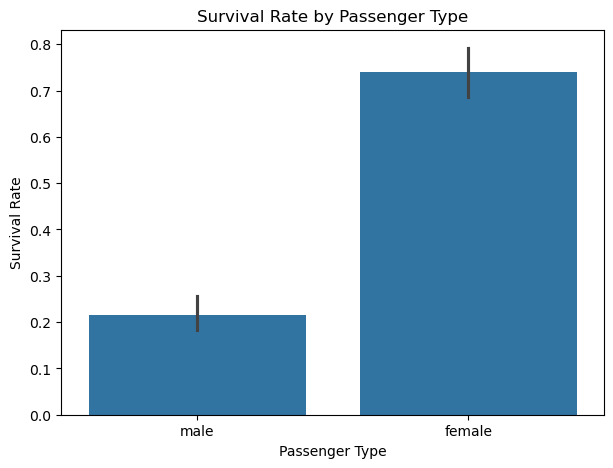

In [180]:
plt.figure(figsize=(7,5))

sns.barplot(
    x='sex',
    y='survived',
    data=df
)

plt.title('Survival Rate by Passenger Type')
plt.xlabel('Passenger Type')
plt.ylabel('Survival Rate')

plt.show()

In [181]:
pd.crosstab(
    df['sex'],
    df['survived'],
    normalize='index'
) * 100

survived,0,1
sex,,
female,25.938567,74.061433
male,78.411405,21.588595


In [182]:
for col in df.columns:
    if df[col].dtype=="object":
        df[col]=pd.Categorical(df[col]).codes

In [183]:
df.head()

,survived,pclass,sex,age,fare,embarked,deck_known,family_size
0,0,3,1,22.0,7.2500,2,0,2
1,1,1,0,38.0,71.2833,0,1,2
2,1,3,0,26.0,7.9250,2,0,1
3,1,1,0,35.0,53.1000,2,1,2
4,0,3,1,35.0,8.0500,2,0,1


# Dicision Tree Model

In [184]:
X = df.drop('survived', axis=1)
y = df['survived']

In [185]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (784, 7)
y shape: (784,)


# Train-test split

In [186]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Build the Decision Tree

In [187]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


# Prediction

In [188]:
y_pred_dt_train = dt_model.predict(X_train)
y_pred_dt = dt_model.predict(X_test)

In [189]:
dt_model.score(X_train,y_train)

0.8083941605839416

In [190]:
dt_model.score(X_test,y_test)

0.8177966101694916

# Evaluate Decision Tree

In [191]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8177966101694916


# classification report:

In [192]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.81      0.91      0.85       139
           1       0.84      0.69      0.76        97

    accuracy                           0.82       236
   macro avg       0.82      0.80      0.81       236
weighted avg       0.82      0.82      0.81       236



# Confusion Matrix

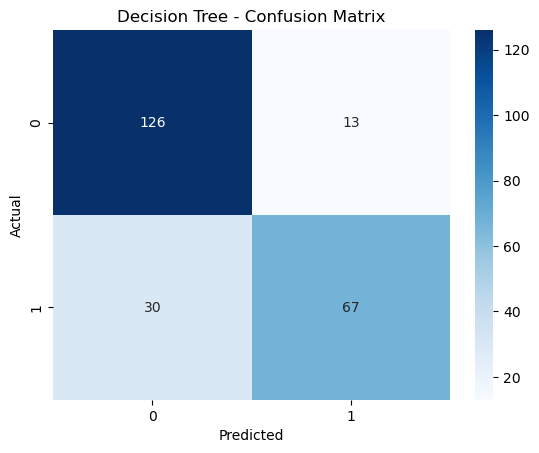

In [193]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Visualize the Decision Tree

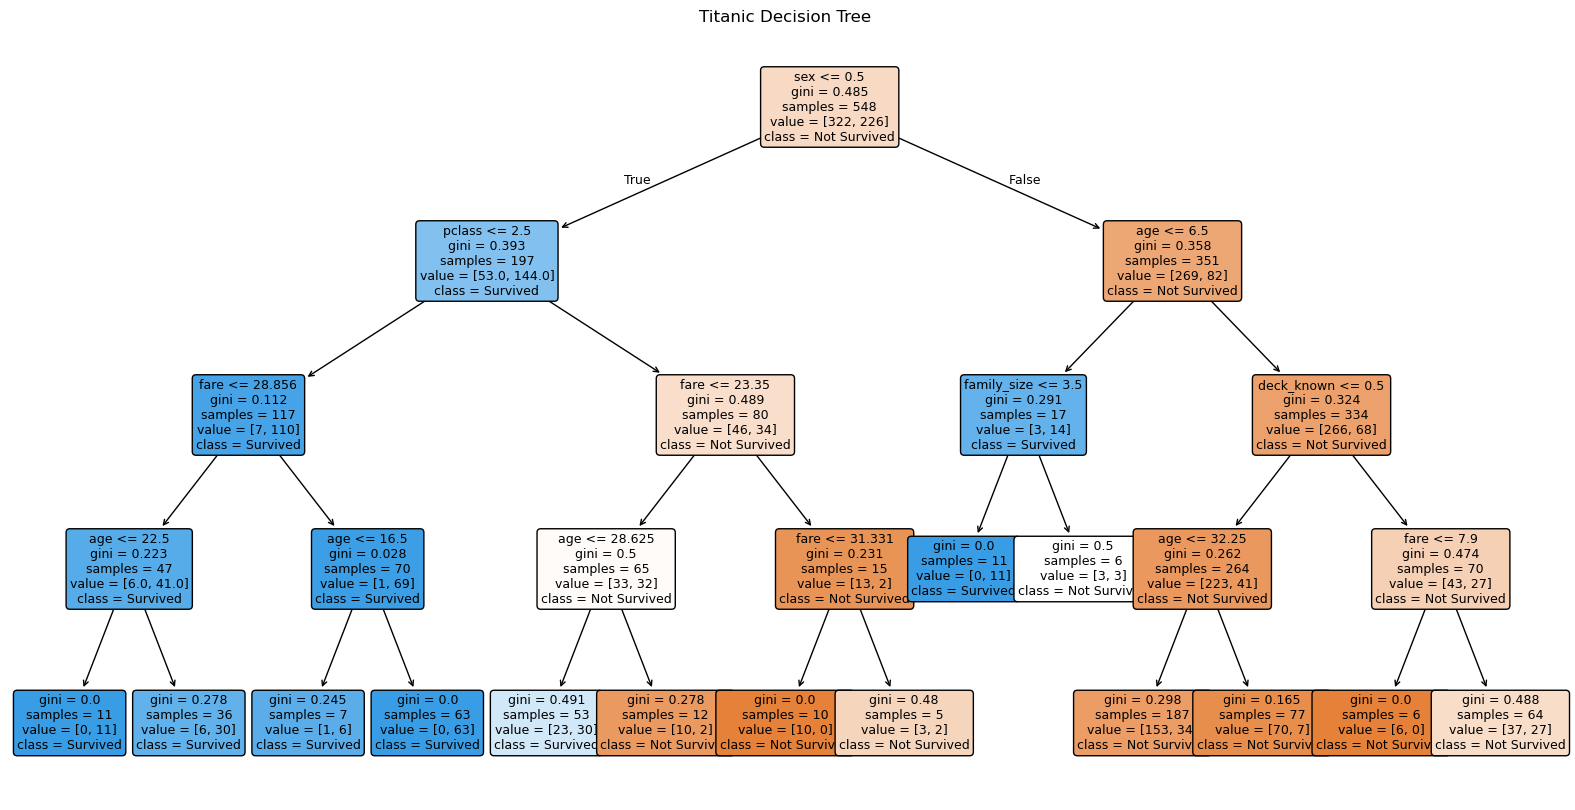

In [194]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Titanic Decision Tree")
plt.show()

# Random Forest

In [195]:
from sklearn.ensemble import RandomForestClassifier

# Create the model

In [196]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Train

In [197]:
rf_model.fit(X_train, y_train)

,n_estimators,500
,criterion,'gini'
,max_depth,4
,min_samples_split,5
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# Prediction

In [198]:
y_pred_rf_train = rf_model.predict(X_train)
y_pred_rf = rf_model.predict(X_test)

In [199]:
rf_model.score(X_train,y_train)

0.822992700729927

In [200]:
rf_model.score(X_test,y_test)

0.809322033898305

# Random Forest Evaluation
Accuracy

In [201]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.809322033898305


# Classification report

In [202]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.77      0.96      0.86       139
           1       0.91      0.60      0.72        97

    accuracy                           0.81       236
   macro avg       0.84      0.78      0.79       236
weighted avg       0.83      0.81      0.80       236



# Confusion matrix

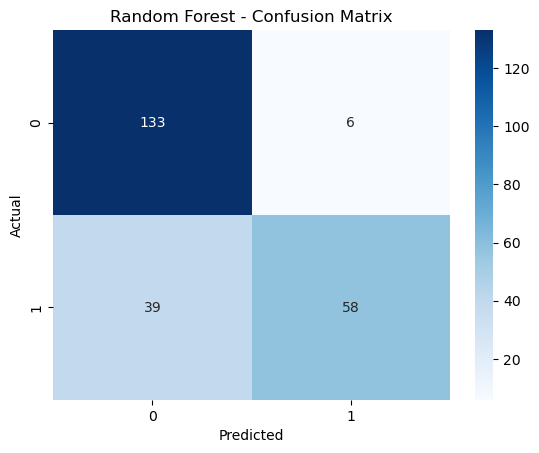

In [203]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Compare Both Models

In [204]:
model_comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        dt_accuracy,
        rf_accuracy
    ]
})

model_comparison

,Model,Accuracy
0,Decision Tree,0.817797
1,Random Forest,0.809322


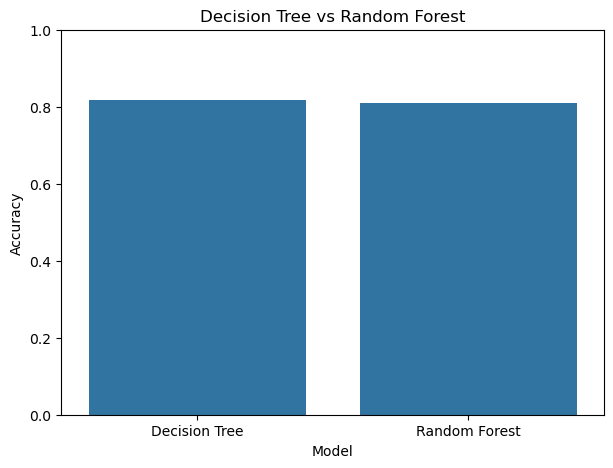

In [205]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy'
)

plt.title('Decision Tree vs Random Forest')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.show()

In [206]:
depths = [2, 3, 4, 5, 6, 7, 8, 10]

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    print(
        "max_depth =", depth,
        "Accuracy =", accuracy_score(y_test, pred)
    )

max_depth = 2 Accuracy = 0.7669491525423728
max_depth = 3 Accuracy = 0.7838983050847458
max_depth = 4 Accuracy = 0.809322033898305
max_depth = 5 Accuracy = 0.7669491525423728
max_depth = 6 Accuracy = 0.8008474576271186
max_depth = 7 Accuracy = 0.7923728813559322
max_depth = 8 Accuracy = 0.7754237288135594
max_depth = 10 Accuracy = 0.7966101694915254


# SAMPLING

In [207]:
#pip install imbalanced-learn

In [208]:
from imblearn.over_sampling import (
    SMOTE,
    ADASYN,
    RandomOverSampler
)

from imblearn.combine import (
    SMOTETomek,
    SMOTEENN
)

from imblearn.pipeline import Pipeline

In [209]:
#X_resampled, y_resampled = SMOTE().fit_resample(X, y)

In [246]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# RandomOverSampler + Decision Tree

In [245]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.tree import DecisionTreeClassifier

ros_dt = Pipeline([
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

ros_dt.fit(X_train, y_train)

y_pred = ros_dt.predict(X_test)

print("RandomOverSampler + Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

RandomOverSampler + Decision Tree
Accuracy: 0.802547770700637
              precision    recall  f1-score   support

           0       0.89      0.76      0.82        92
           1       0.72      0.86      0.78        65

    accuracy                           0.80       157
   macro avg       0.80      0.81      0.80       157
weighted avg       0.82      0.80      0.80       157

[[70 22]
 [ 9 56]]


# SMOTE + Decision Tree

In [227]:
smote_dt = Pipeline([
    ('sampler', SMOTE(random_state=42)),
    ('classifier', DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

smote_dt.fit(X_train, y_train)

y_pred = smote_dt.predict(X_test)

print("SMOTE + Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTE + Decision Tree
Accuracy: 0.7961783439490446
              precision    recall  f1-score   support

           0       0.83      0.82      0.82        92
           1       0.75      0.77      0.76        65

    accuracy                           0.80       157
   macro avg       0.79      0.79      0.79       157
weighted avg       0.80      0.80      0.80       157

[[75 17]
 [15 50]]


# ADASYN + Decision Tree

In [228]:
adasyn_dt = Pipeline([
    ('sampler', ADASYN(random_state=42)),
    ('classifier', DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

adasyn_dt.fit(X_train, y_train)

y_pred = adasyn_dt.predict(X_test)

print("ADASYN + Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

ADASYN + Decision Tree
Accuracy: 0.8280254777070064
              precision    recall  f1-score   support

           0       0.81      0.92      0.86        92
           1       0.87      0.69      0.77        65

    accuracy                           0.83       157
   macro avg       0.84      0.81      0.82       157
weighted avg       0.83      0.83      0.82       157

[[85  7]
 [20 45]]


# SMOTE-Tomek + Decision Tree

In [229]:
smote_tomek_dt = Pipeline([
    ('sampler', SMOTETomek(random_state=42)),
    ('classifier', DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

smote_tomek_dt.fit(X_train, y_train)

y_pred = smote_tomek_dt.predict(X_test)

print("SMOTE-Tomek + Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTE-Tomek + Decision Tree
Accuracy: 0.802547770700637
              precision    recall  f1-score   support

           0       0.78      0.92      0.85        92
           1       0.85      0.63      0.73        65

    accuracy                           0.80       157
   macro avg       0.82      0.78      0.79       157
weighted avg       0.81      0.80      0.80       157

[[85  7]
 [24 41]]


# SMOTEENN + Decision Tree

In [230]:
smote_enn_dt = Pipeline([
    ('sampler', SMOTEENN(random_state=42)),
    ('classifier', DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ))
])

smote_enn_dt.fit(X_train, y_train)

y_pred = smote_enn_dt.predict(X_test)

print("SMOTEENN + Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTEENN + Decision Tree
Accuracy: 0.7707006369426752
              precision    recall  f1-score   support

           0       0.84      0.75      0.79        92
           1       0.69      0.80      0.74        65

    accuracy                           0.77       157
   macro avg       0.77      0.78      0.77       157
weighted avg       0.78      0.77      0.77       157

[[69 23]
 [13 52]]


# SMOTE + RandomForest

In [231]:
smote_rf = Pipeline([
    ('sampler', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        random_state=42,
        n_jobs=-1
    ))
])

smote_rf.fit(X_train, y_train)

y_pred = smote_rf.predict(X_test)

print("SMOTE + Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTE + Random Forest
Accuracy: 0.8280254777070064
              precision    recall  f1-score   support

           0       0.89      0.80      0.85        92
           1       0.76      0.86      0.81        65

    accuracy                           0.83       157
   macro avg       0.82      0.83      0.83       157
weighted avg       0.84      0.83      0.83       157

[[74 18]
 [ 9 56]]


# RandomOverSampler + RandomForest

In [232]:
ros_rf = Pipeline([
    ('sampler', RandomOverSampler(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        random_state=42,
        n_jobs=-1
    ))
])

ros_rf.fit(X_train, y_train)

y_pred = smote_rf.predict(X_test)

print("SMOTE + Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTE + Random Forest
Accuracy: 0.8280254777070064
              precision    recall  f1-score   support

           0       0.89      0.80      0.85        92
           1       0.76      0.86      0.81        65

    accuracy                           0.83       157
   macro avg       0.82      0.83      0.83       157
weighted avg       0.84      0.83      0.83       157

[[74 18]
 [ 9 56]]


# ADASYN + RandomForest

In [250]:
adasyn_rf = Pipeline([
    ('sampler', ADASYN(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        random_state=42,
        n_jobs=-1
    ))
])

adasyn_rf.fit(X_train, y_train)

y_pred = smote_rf.predict(X_test)

print("SMOTE + Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTE + Random Forest
Accuracy: 0.8280254777070064
              precision    recall  f1-score   support

           0       0.89      0.80      0.85        92
           1       0.76      0.86      0.81        65

    accuracy                           0.83       157
   macro avg       0.82      0.83      0.83       157
weighted avg       0.84      0.83      0.83       157

[[74 18]
 [ 9 56]]


# SMOTETomek + RandomForest

In [251]:
smoteTK_rf = Pipeline([
    ('sampler', SMOTETomek(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        random_state=42,
        n_jobs=-1
    ))
])

smoteTK_rf.fit(X_train, y_train)

y_pred = smote_rf.predict(X_test)

print("SMOTE + Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTE + Random Forest
Accuracy: 0.8280254777070064
              precision    recall  f1-score   support

           0       0.89      0.80      0.85        92
           1       0.76      0.86      0.81        65

    accuracy                           0.83       157
   macro avg       0.82      0.83      0.83       157
weighted avg       0.84      0.83      0.83       157

[[74 18]
 [ 9 56]]


# SMOTEENN + RandomForest

In [235]:
smoteenn_rf = Pipeline([
    ('sampler', SMOTEENN(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        random_state=42,
        n_jobs=-1
    ))
])

smoteenn_rf.fit(X_train, y_train)

y_pred = smote_rf.predict(X_test)

print("SMOTE + Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

SMOTE + Random Forest
Accuracy: 0.8280254777070064
              precision    recall  f1-score   support

           0       0.89      0.80      0.85        92
           1       0.76      0.86      0.81        65

    accuracy                           0.83       157
   macro avg       0.82      0.83      0.83       157
weighted avg       0.84      0.83      0.83       157

[[74 18]
 [ 9 56]]


# BaggingClassifier + DataTree

In [236]:
from sklearn.ensemble import BaggingClassifier

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

y_pred_bag = bagging_model.predict(X_test)

print("Bagging Classifier")
print("Accuracy:", accuracy_score(y_test, y_pred_bag))
print(classification_report(y_test, y_pred_bag))
print(confusion_matrix(y_test, y_pred))

Bagging Classifier
Accuracy: 0.8152866242038217
              precision    recall  f1-score   support

           0       0.78      0.96      0.86        92
           1       0.91      0.62      0.73        65

    accuracy                           0.82       157
   macro avg       0.84      0.79      0.80       157
weighted avg       0.83      0.82      0.81       157

[[74 18]
 [ 9 56]]


# BaggingClassifier + RandomForest

In [252]:
from sklearn.ensemble import BaggingClassifier

bagging_model = BaggingClassifier(
    estimator=RandomForestClassifier(
        max_depth=4,
        random_state=42
    ),
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

y_pred_bag = bagging_model.predict(X_test)

print("Bagging Classifier")
print("Accuracy:", accuracy_score(y_test, y_pred_bag))
print(classification_report(y_test, y_pred_bag))
print(confusion_matrix(y_test, y_pred_bag))

Bagging Classifier
Accuracy: 0.8152866242038217
              precision    recall  f1-score   support

           0       0.79      0.92      0.85        92
           1       0.86      0.66      0.75        65

    accuracy                           0.82       157
   macro avg       0.83      0.79      0.80       157
weighted avg       0.82      0.82      0.81       157

[[85  7]
 [22 43]]


In [238]:
models = {

    # Baseline models
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        random_state=42,
        n_jobs=-1
    ),

    # Decision Tree + sampling
    "ROS + Decision Tree": Pipeline([
        ("sampler", RandomOverSampler(random_state=42)),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ]),

    "SMOTE + Decision Tree": Pipeline([
        ("sampler", SMOTE(random_state=42)),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ]),

    "ADASYN + Decision Tree": Pipeline([
        ("sampler", ADASYN(random_state=42)),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ]),

    "SMOTE-Tomek + Decision Tree": Pipeline([
        ("sampler", SMOTETomek(random_state=42)),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ]),

    "SMOTEENN + Decision Tree": Pipeline([
        ("sampler", SMOTEENN(random_state=42)),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ]),

    # Random Forest + sampling
    "ROS + Random Forest": Pipeline([
        ("sampler", RandomOverSampler(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SMOTE + Random Forest": Pipeline([
        ("sampler", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "ADASYN + Random Forest": Pipeline([
        ("sampler", ADASYN(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SMOTE-Tomek + Random Forest": Pipeline([
        ("sampler", SMOTETomek(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "SMOTEENN + Random Forest": Pipeline([
        ("sampler", SMOTEENN(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    # Bagging
    "Bagging Classifier DT": BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ),
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Bagging Classifier RF": BaggingClassifier(
        estimator=RandomForestClassifier(
            max_depth=4,
            random_state=42
        ),
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

In [243]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,ROS + Random Forest,0.834395,0.760000,0.876923,0.814286
1,SMOTE-Tomek + Random Forest,0.834395,0.767123,0.861538,0.811594
2,ADASYN + Decision Tree,0.828025,0.865385,0.692308,0.769231
3,SMOTE + Random Forest,0.828025,0.756757,0.861538,0.805755
4,Random Forest,0.821656,0.877551,0.661538,0.754386
5,ADASYN + Random Forest,0.821656,0.753425,0.846154,0.797101
6,Bagging Classifier DT,0.815287,0.909091,0.615385,0.733945
7,Bagging Classifier RF,0.815287,0.860000,0.661538,0.747826
8,ROS + Decision Tree,0.802548,0.717949,0.861538,0.783217
9,SMOTE-Tomek + Decision Tree,0.802548,0.854167,0.630769,0.725664
